# setup-MCAR-holdout
9.16.25

Sets up the holdout experiment in MCAR mode. This might honestly be a better idea considering the Amyloid-$B$
peptides that we care about are relatively high abundance. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys

sys.path.append("../../../bin/")

from utils import mcar_partition

sns.set(context="talk", style="ticks") 
pal = sns.color_palette()

#### Configs 

In [2]:
# The file paths
quants_path="../quant-reports/SMTG-mod-fasta-unimputed-report.csv"
rts_path="../RT-matrices/SMTG-DIANN-lib.csv"

# The partitioning params
min_pres=4
test_frac=0.5
rand_state=18

#### Read in the Skyline quants report 

In [3]:
quants_df = pd.read_csv(quants_path)
quants_df = quants_df[quants_df["Protein Name"] != "Decoys"]
quants_df = quants_df.drop_duplicates(subset=["Peptide Modified Sequence"], keep="first")
quants_df.index = quants_df["Peptide Modified Sequence"]
quants_df = quants_df.drop(columns=["Peptide Modified Sequence", "Precursor Charge", "Protein Name"])

quants_df = quants_df.sort_index()

print(quants_df.shape)
#quants_df.head(2)

(95264, 78)


#### Read in the RTs dataframe

In [4]:
rts_df = pd.read_csv(rts_path, index_col=0)
rts_df = rts_df.drop_duplicates(subset=["peptideModSeq"], keep="first")
rts_df.index = rts_df["peptideModSeq"]
rts_df = rts_df.drop(columns=["peptideModSeq"])
rts_df = rts_df.sort_index()
rts_df = rts_df.drop_duplicates(keep="first")

print(rts_df.shape)
#rts_df.head(2)

(131860, 156)


#### Subset down both quants and RT matrices to the shared peptide IDs
Why are there so relatively few shared peptide IDs? 

In [5]:
shared_ids = np.intersect1d(np.array(quants_df.index), np.array(rts_df.index))

quants_df = quants_df.loc[shared_ids]
rts_df = rts_df.loc[shared_ids]

print(quants_df.shape)
print(rts_df.shape)

(77425, 78)
(77425, 156)


#### Drop the unwanted columns 

In [6]:
toremove0 = []
for x in quants_df.columns:
    if ("Lib" in x) or ("TRP" in x) or ("HAD" in x): 
        toremove0.append(x)

toremove1 = []
for x in rts_df.columns:
    if ("Lib" in x) or ("TRP" in x) or ("HAD" in x): 
        toremove1.append(x)

quants_df = quants_df.drop(toremove0, axis=1)
rts_df = rts_df.drop(toremove1, axis=1)

#### Rename the columns in the quants dataframe 

In [7]:
newcols_quants = [x.split(" ")[0].split("-")[-1] for x in quants_df.columns]
quants_df.columns = newcols_quants

#### Rename the columns in the RTs dataframe 

In [8]:
start_end_ids = [x.split(" ")[0].split(".")[1].replace("Time", "") for x in rts_df.columns]
sample_ids = [x.split("-")[-1].replace(")", "") for x in rts_df.columns]

zipped = zip(start_end_ids, sample_ids)

new_ids_RT = []
for x, y in zipped:
    new_id = y + "_" + x 
    new_ids_RT.append(new_id)

rts_df.columns = new_ids_RT

#### Subset down the RTs dataframe to only include the same samples as the quants dataframe 

In [9]:
rts_ids = [x.split("_")[0] for x in rts_df.columns]

keep_cols = []
for x in rts_ids: 
    curr = False
    if x in list(quants_df.columns):
        curr = True
    keep_cols.append(curr)

rts_df = rts_df[rts_df.columns[keep_cols]]

#### The sizes should now match 

In [10]:
print(rts_df.shape)
print(quants_df.shape)

(77425, 124)
(77425, 62)


#### Break down into separate RT start and end dataframes 

In [11]:
cols_arr = np.array(rts_df.columns)
start_bool = np.array(["start" in x for x in cols_arr])
start_ids = cols_arr[start_bool]
end_ids = cols_arr[~start_bool]

rt_starts_df = rts_df[start_ids]
rt_ends_df = rts_df[end_ids]

# For the eventual missingess calculation
rt_starts_df_orig = rt_starts_df.copy()

print(rt_starts_df.shape)
print(rt_ends_df.shape)

(77425, 62)
(77425, 62)


#### Column-wise sort all three dataframes 

In [12]:
rt_starts_df = rt_starts_df.sort_index(axis=1)
rt_ends_df = rt_ends_df.sort_index(axis=1)
quants_df = quants_df.sort_index(axis=1)

#### Do the MCAR holdout on the quants dataframe 

In [13]:
quants_df[quants_df == 0.0] = 1e-6
quants_df = np.log2(quants_df)

quants_mat = np.array(quants_df)

train_mat, test_mat, mask = mcar_partition(
    matrix=quants_mat,
    test_frac=test_frac,
    min_present=min_pres,
    random_state=rand_state, 
)
print(train_mat.shape)

(77425, 62)


#### Remove the proteins with too few present values
This adds an additional layer of complexity but may be important. 

In [14]:
num_present = np.sum(~np.isnan(train_mat), axis=1)
discard = num_present < min_pres
num_discard = discard.sum()

train_mat = np.delete(train_mat, discard, axis=0)
test_mat = np.delete(test_mat, discard, axis=0)
keep_rows = np.delete(np.array(quants_df.index), discard)
mask = np.delete(mask, discard, axis=0)

mask_df = pd.DataFrame(mask, columns=quants_df.columns, index=keep_rows)
print(mask_df.shape)

(67287, 62)


#### Plot the distribution of the train and test sets

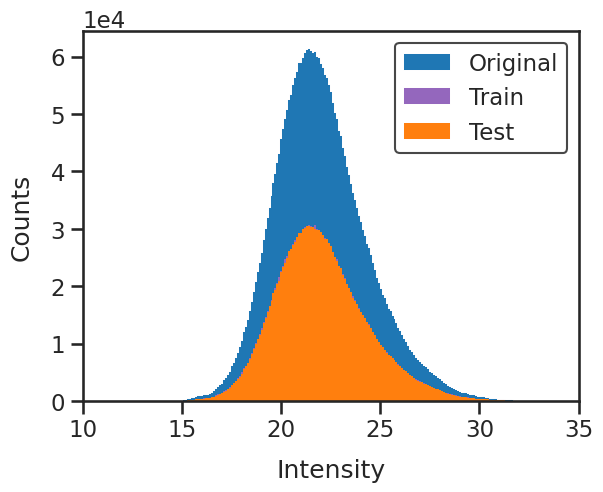

In [15]:
# Flatten
orig_rav = quants_mat.ravel()[~np.isnan(quants_mat.ravel())]
train_rav = train_mat.ravel()
test_rav = test_mat.ravel()

# Get present values from the training matrix
train_nans = np.isnan(train_rav)
train_present = train_rav[~train_nans]

test_nans = np.isnan(test_rav)
test_present = test_rav[~test_nans]

# Get the means
train_mean = np.around(np.mean(train_present), 2)
test_mean = np.around(np.mean(test_present), 2)

binwidth=0.1

# Plot
plt.figure()
plt.hist(
    orig_rav, 
    density=False, 
    bins=np.arange(min(orig_rav), max(orig_rav) + binwidth, binwidth),
    linewidth=0.01, 
    color='#1f77b4', 
    edgecolor='#1f77b4',
    alpha=1.0, 
    label="Original",
)
plt.hist(
    train_present, 
    density=False, 
    bins=np.arange(min(orig_rav), max(orig_rav) + binwidth, binwidth),
    linewidth=0.01, 
    color='#9467bd', 
    edgecolor='#9467bd', 
    alpha=1.0, 
    label="Train",
)
plt.hist(
    test_present,
    density=False, 
    linewidth=0.01, 
    color='#ff7f0e', 
    edgecolor='#ff7f0e', 
    bins=np.arange(min(orig_rav), max(orig_rav) + binwidth, binwidth),
    alpha=1.0, 
    label="Test",
)
plt.minorticks_off()

plt.xlabel("Intensity", labelpad=12)
plt.ylabel("Counts", labelpad=12)

plt.legend(bbox_to_anchor=(1.0, 1.0), edgecolor="k")
# for lh in leg.legendHandles: 
#     lh.set_alpha(1)

plt.xlim(10, 35)

plt.ticklabel_format(style="sci", axis="y", scilimits=(0,0))
#plt.savefig("../figures/MCAR-holdout-distributions.pdf", bbox_inches="tight")

#### Mask the RTs matrices
In the mask array, TRUE means that a value should be masked, that is, selected for the test set. 

In [16]:
rt_starts_arr = np.delete(rt_starts_df, discard, axis=0)
rt_ends_arr = np.delete(rt_ends_df, discard, axis=0)

rt_starts_df_filt = pd.DataFrame(rt_starts_arr, columns=rt_starts_df.columns, index=keep_rows)
rt_ends_df_filt = pd.DataFrame(rt_ends_arr, columns=rt_ends_df.columns, index=keep_rows)

mask = np.array(mask_df)
rt_starts_df_filt[~mask] = np.nan
rt_ends_df_filt[~mask] = np.nan

#### Combine into a single dataframe of RT starts and ends

In [17]:
rts_df_masked = pd.concat([rt_starts_df_filt, rt_ends_df_filt], axis=1)
rts_df_masked = rts_df_masked[rts_df.columns]

#### Match the new RT column IDs up with the original versions
This is maybe the hardest part. But we can't write the blib unless the column IDs match the names of
the mzML files. 

In [18]:
rts_df_orig = pd.read_csv(rts_path, index_col=0)

new_ids = []
for colname in rts_df_masked.columns:  
    sample_id = colname.split("_")[0]
    start_end_id = colname.split("_")[1]
    
    for colname_orig in rts_df_orig.columns:
        if sample_id in colname_orig:
            if start_end_id == "start": 
                new_ids.append(colname_orig)

rts_df_masked.columns = new_ids
rts_df_masked.index.name = "peptideModSeq"
print(rts_df_masked.shape)
rts_df_masked.head(4)

(67287, 124)


,rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR04),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR04),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR08),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR08),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR13),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR13),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR20),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR20),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR16),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR16),...,rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR58),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR58),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR44),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR44),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR53),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR53),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B3-ind-8mz-ovlp-400to1000-TZR35),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B3-ind-8mz-ovlp-400to1000-TZR35),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR52),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR52)
peptideModSeq,,,,,,,,,,,,,,,,,,,,,
AAAAAAAAQMHAK,NaN,NaN,NaN,NaN,25.246702,25.674000,NaN,NaN,NaN,NaN,...,25.369999,25.737101,25.069601,26.041901,25.296402,25.784500,25.512701,25.756401,25.488199,25.913799
AAAAAAALQAK,33.974304,34.578197,34.395802,34.818897,34.110798,34.714901,NaN,NaN,NaN,NaN,...,34.246304,34.670197,NaN,NaN,33.919598,34.463402,NaN,NaN,34.291199,34.653698
AAAAAASGGSR,NaN,NaN,15.672400,16.037701,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,15.475100,15.781700,NaN,NaN,NaN,NaN
AAAAAWEEPSSGNGTAR,NaN,NaN,NaN,NaN,NaN,NaN,48.2939,48.535599,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,48.779099,49.203400


#### How much of the data did we mask? 
This number may be significantly below what we intended just because we end up throwing a lot of the
super high missingness peptides out. 

In [19]:
nan_count_orig = np.count_nonzero(np.isnan(rt_starts_df_orig))
nan_frac_orig = nan_count_orig / rt_starts_df_orig.size
print(f"original MV fraction: {np.around(nan_frac_orig, 3)}")

nan_count_masked = np.count_nonzero(np.isnan(rt_starts_df_filt))
nan_frac_masked = nan_count_masked / rt_starts_df_filt.size
print(f"post-mask MV fraction: {np.around(nan_frac_masked, 3)}")

adnl_mv = nan_frac_masked - nan_frac_orig
print(f"additional MV fraction: {np.around(adnl_mv, 3)}")

original MV fraction: 0.32
post-mask MV fraction: 0.611
additional MV fraction: 0.292


#### Check the missingness fractions of the two Amyloid-$B$ peptides specifically 

In [20]:
lvf_arr = np.array(rts_df_masked.loc["LVFFAEDVGSNK"])
hds_arr = np.array(rts_df_masked.loc["HDSGYEVHHQK"])

lvf_mv_frac = np.count_nonzero(np.isnan(lvf_arr)) / len(lvf_arr)
hds_mv_frac = np.count_nonzero(np.isnan(hds_arr)) / len(hds_arr)

print(f"LVF peptide MV frac: {np.around(lvf_mv_frac, 2)}")
print(f"HDS peptide MV frac: {np.around(hds_mv_frac, 2)}")

LVF peptide MV frac: 0.55
HDS peptide MV frac: 0.4


In [21]:
pd.set_option('display.max_columns', 500)
#rts_df_masked[rts_df_masked.index == "LVFFAEDVGSNK"]
rts_df_masked[rts_df_masked.index == "HDSGYEVHHQK"]

,rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR04),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR04),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR08),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR08),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR13),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR13),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR20),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR20),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR16),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR16),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR11),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR11),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR51),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR51),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR15),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR15),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B3-ind-8mz-ovlp-400to1000-TZR33),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B3-ind-8mz-ovlp-400to1000-TZR33),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR55),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR55),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B3-ind-8mz-ovlp-400to1000-TZR38),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B3-ind-8mz-ovlp-400to1000-TZR38),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B3-ind-8mz-ovlp-400to1000-TZR29),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B3-ind-8mz-ovlp-400to1000-TZR29),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR47),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR47),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR43),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR43),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR50),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR50),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR59),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR59),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR03),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR03),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR07),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR07),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR62),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR62),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR26),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to1000-TZR26),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR12),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR12),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR01),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR01),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR09),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR09),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR02),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B1-ind-8mz-ovlp-400to1000-TZR02),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR49),rt.endTime (24April2019-Lumos-DIA-HuAD-SMTG-B4-5-ind-8mz-ovlp-400to1000-TZR49),rt.startTime (24April2019-Lumos-DIA-HuAD-SMTG-B2-ind-8mz-ovlp-400to

#### Write that sucker

In [22]:
#rts_df_masked.to_csv("../RT-matrices/SMTG-DIANN-lib-MCAR-holdout.csv")

#### Sanity check 

In [23]:
# rt_df = pd.read_csv("../RT-matrices/SMTG-DIANN-lib-MCAR-holdout.csv")
# rt_df.index = rt_df["peptideModSeq"]
# rt_df = rt_df.drop(columns=["peptideModSeq"])
# rt_df